In [ ]:
from google.colab import drive
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/data_e_comer/ecommerce_sales_customer_analytics_150k.csv'

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [ ]:
# Konfiguracja stylu wykresów
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.titlesize': 14, 'axes.titlesize': 12, 'axes.labelsize': 11})

df = pd.read_csv(file_path)

# Standaryzacja nazw kolumn (usunięcie spacji, małe litery)
df.columns = [c.strip() for c in df.columns]

print(f"Liczba rekordów: {df.shape[0]:,}")
print(f"Liczba kolumn: {df.shape[1]}")
df.head(3)

Liczba rekordów: 138,116
Liczba kolumn: 46


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6


# 1. Analiza Marży vs. Rabaty

In [ ]:
# 1. Standaryzacja kolumn rabatu i marży
# Sprawdzamy rzeczywiste nazwy kolumn w wczytanym zbiorze danych
discount_col = 'discount_amount' if 'discount_amount' in df.columns else ('discount' if 'discount' in df.columns else None)
margin_col = 'profit_margin_percentage' if 'profit_margin_percentage' in df.columns else 'Profit_Margin'

if margin_col not in df.columns:
    if 'profit' in df.columns and 'net_sales' in df.columns:
        df['profit_margin_percentage'] = (df['profit'] / df['net_sales']) * 100
        margin_col = 'profit_margin_percentage'

# Tworzenie przedziałów (binned) dla wartości rabatu
if discount_col in df.columns:
    if df[discount_col].max() <= 1.0:
        df['Discount_Bin'] = (df[discount_col] * 100).round().astype(int)
    else:
        df['Discount_Bin'] = df[discount_col].round().astype(int)
else:
    raise KeyError("Nie znaleziono odpowiedniej kolumny z rabatem (szukano 'discount_amount' / 'discount')")

In [ ]:
# 2. Agregacja marży wg poziomu rabatu
margin_by_discount = df.groupby('Discount_Bin').agg(
    mean_margin=(margin_col, 'mean'),
    median_margin=(margin_col, 'median'),
    q25_margin=(margin_col, lambda x: np.percentile(x, 25)),
    q75_margin=(margin_col, lambda x: np.percentile(x, 75)),
    transaction_count=(margin_col, 'count')
).reset_index()

In [ ]:
# Wyznaczenie punktu krytycznego (przecięcie marży = 0)
breakeven_points = margin_by_discount[margin_by_discount['mean_margin'] <= 0]
breakeven_discount = breakeven_points['Discount_Bin'].min() if not breakeven_points.empty else None

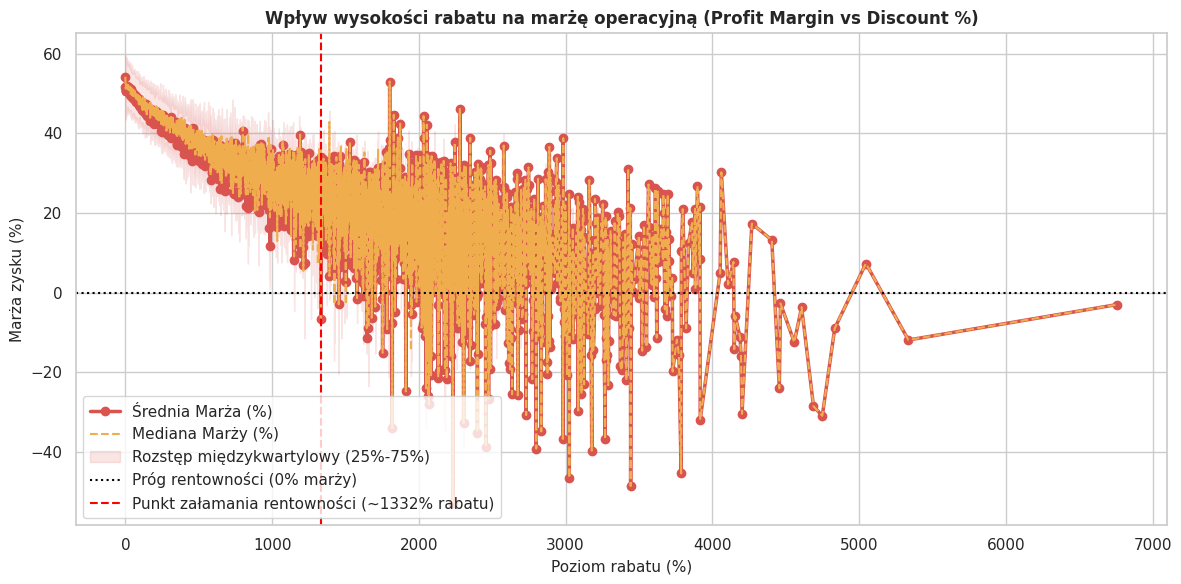

👉 WNIOSEK: Marża spada poniżej zera przy rabacie na poziomie: 1332%.


In [ ]:
# 3. Wizualizacja: Linia trendu marży z przedziałem międzykwartylowym
plt.figure(figsize=(12, 6))

plt.plot(margin_by_discount['Discount_Bin'], margin_by_discount['mean_margin'],
         color='#d9534f', linewidth=2.5, marker='o', label='Średnia Marża (%)')
plt.plot(margin_by_discount['Discount_Bin'], margin_by_discount['median_margin'],
         color='#f0ad4e', linestyle='--', label='Mediana Marży (%)')
plt.fill_between(margin_by_discount['Discount_Bin'],
                 margin_by_discount['q25_margin'],
                 margin_by_discount['q75_margin'],
                 color='#d9534f', alpha=0.15, label='Rozstęp międzykwartylowy (25%-75%)')

plt.axhline(0, color='black', linestyle=':', linewidth=1.5, label='Próg rentowności (0% marży)')

if breakeven_discount is not None:
    plt.axvline(breakeven_discount, color='red', linestyle='--', linewidth=1.5,
                label=f'Punkt załamania rentowności (~{breakeven_discount}% rabatu)')

plt.title('Wpływ wysokości rabatu na marżę operacyjną (Profit Margin vs Discount %)', fontweight='bold')
plt.xlabel('Poziom rabatu (%)')
plt.ylabel('Marża zysku (%)')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

if breakeven_discount:
    print(f"👉 WNIOSEK: Marża spada poniżej zera przy rabacie na poziomie: {breakeven_discount}%.")

# 2. Wpływ logistyki na zwroty i oceny

In [ ]:
#1. Konwersja statusu zwrotu na wartość binarną 0/1
return_col = next((col for col in df.columns if col.lower() == 'return_status'), None)

if return_col is None:
    return_col = next((col for col in df.columns if 'return' in col.lower()), None)

if return_col in df.columns:
    if df[return_col].dtype == 'object':
        df['is_returned'] = df[return_col].astype(str).str.lower().isin(['1', 'yes', 'returned', 'true']).astype(int)
    else:
        df['is_returned'] = df[return_col].fillna(0).astype(int)
else:
    raise KeyError("Nie znaleziono kolumny dotyczącej zwrotów (szukano np. 'return_status')")

In [ ]:
# 2. Agregacja wskaźnika zwrotów i średniej oceny wg dni dostawy
delivery_days_col = next((col for col in df.columns if 'delivery_days' in col.lower()), 'delivery_days')
ratings_col = next((col for col in df.columns if 'rating' in col.lower()), 'customer_rating')

delivery_impact = df.groupby(delivery_days_col).agg(
    return_rate=('is_returned', lambda x: x.mean() * 100),
    avg_rating=(ratings_col, 'mean'),
    order_volume=(ratings_col, 'count')
).reset_index()

# Filtrowanie rzadkich wartości skrajnych (np. poniżej 50 zamówień)
delivery_impact = delivery_impact[delivery_impact['order_volume'] >= 50]

# Identyfikacja progu, gdzie ocena spada poniżej 4.0
sub_4_rating = delivery_impact[delivery_impact['avg_rating'] < 4.0]
critical_delivery_day = sub_4_rating[delivery_days_col].min() if not sub_4_rating.empty else None

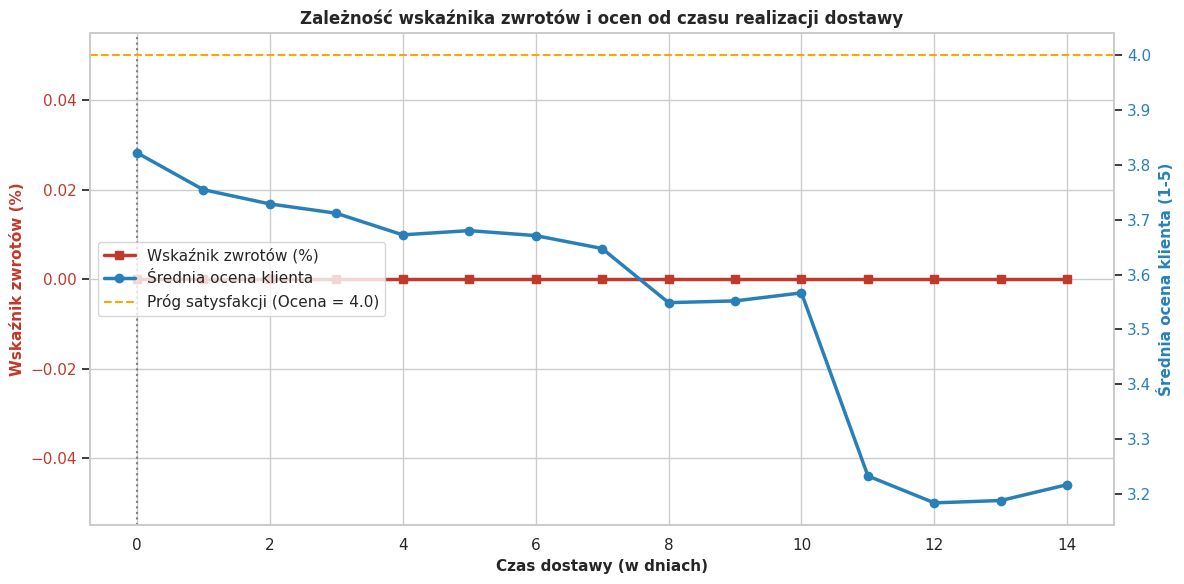

👉 WNIOSEK: Średnia ocena klienta spada trwale poniżej 4.0 począwszy od 0.0. dnia dostawy.


In [ ]:
# 3. Wizualizacja: Podwójna oś Y (Dual-Axis Plot)
fig, ax1 = plt.subplots(figsize=(12, 6))

color_returns = '#c0392b'
color_rating = '#2980b9'

# Oś 1: Wskaźnik zwrotów (Return Rate)
ax1.set_xlabel('Czas dostawy (w dniach)', fontweight='bold')
ax1.set_ylabel('Wskaźnik zwrotów (%)', color=color_returns, fontweight='bold')
line1 = ax1.plot(delivery_impact[delivery_days_col], delivery_impact['return_rate'],
                 color=color_returns, marker='s', linewidth=2.5, label='Wskaźnik zwrotów (%)')
ax1.tick_params(axis='y', labelcolor=color_returns)

# Oś 2: Średnia ocena (Customer Rating)
ax2 = ax1.twinx()
ax2.set_ylabel('Średnia ocena klienta (1-5)', color=color_rating, fontweight='bold')
line2 = ax2.plot(delivery_impact[delivery_days_col], delivery_impact['avg_rating'],
                 color=color_rating, marker='o', linewidth=2.5, label='Średnia ocena klienta')
ax2.tick_params(axis='y', labelcolor=color_rating)
ax2.grid(False)

# Linia referencyjna oceny = 4.0
ax2.axhline(4.0, color='orange', linestyle='--', linewidth=1.5, label='Próg satysfakcji (Ocena = 4.0)')

if critical_delivery_day is not None:
    ax1.axvline(critical_delivery_day, color='gray', linestyle=':', linewidth=1.5,
                label=f'Krytyczny czas dostawy ({critical_delivery_day} dni)')

# Łączona legenda
lines = line1 + line2 + [ax2.lines[-1]]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center left')

plt.title('Zależność wskaźnika zwrotów i ocen od czasu realizacji dostawy', fontweight='bold')
plt.tight_layout()
plt.show()

if critical_delivery_day is not None:
    print(f"👉 WNIOSEK: Średnia ocena klienta spada trwale poniżej 4.0 począwszy od {critical_delivery_day}. dnia dostawy.")

# 3. Segmentacja Klientów

In [ ]:
# 1. Przygotowanie daty referencyjnej do wyliczenia Recency
order_date_col = next((col for col in df.columns if col.lower() == 'order_date'), 'order_date')
df[order_date_col] = pd.to_datetime(df[order_date_col])
snapshot_date = df[order_date_col].max() + pd.Timedelta(days=1)

# Wybór kolumny wartości pieniężnej transakcji (np. 'sales' lub 'net_sales')
sales_col = next((col for col in df.columns if col.lower() in ['sales', 'net_sales', 'revenue']), 'sales')

In [ ]:
# 2. Obliczenie wskaźników RFM z obsługą wielkości liter w nazwach kolumn
customer_id_col = next((col for col in df.columns if col.lower() == 'customer_id'), 'customer_id')
order_id_col = next((col for col in df.columns if col.lower() == 'order_id'), 'order_id')

rfm = df.groupby(customer_id_col).agg(
    Recency=(order_date_col, lambda x: (snapshot_date - x.max()).days),
    Frequency=(order_id_col, 'nunique'),
    Monetary=(sales_col, 'sum')
).reset_index()

# Ujednolicenie nazw kolumn w nowej tabeli rfm dla kolejnych kroków
rfm.rename(columns={customer_id_col: 'Customer_ID'}, inplace=True)

In [ ]:
# 3. Przypisanie kwartyli (Skale 1-4)
# R_Score: im mniejszy Recency (dni), tym wyższa ocena
rfm['R_score'] = pd.qcut(rfm['Recency'], q=4, labels=[4, 3, 2, 1])

# Frequency i Monetary: im wyższe, tym lepsza ocena
rfm['F_score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=[1, 2, 3, 4])
rfm['M_score'] = pd.qcut(rfm['Monetary'].rank(method='first'), q=4, labels=[1, 2, 3, 4])

rfm['R_score'] = rfm['R_score'].astype(int)
rfm['F_score'] = rfm['F_score'].astype(int)
rfm['M_score'] = rfm['M_score'].astype(int)

In [ ]:
#4. Mapowanie segmentów biznesowych na bazie reguł R i F
def segment_customer(row):
    r, f = row['R_score'], row['F_score']
    if r >= 4 and f >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3:
        return 'Loyal Customers'
    elif r >= 3 and f <= 2:
        return 'Potential Loyalists'
    elif r <= 2 and f >= 3:
        return 'At-Risk'
    elif r <= 2 and f <= 2:
        return 'Hibernating / Lost'
    return 'Other'


rfm['Segment'] = rfm.apply(segment_customer, axis=1)

In [ ]:
# 5. Zestawienie udziału procentowego bazy i średniej wartości klienta (LTV)
segment_summary = rfm.groupby('Segment').agg(
    Customer_Count=('Customer_ID', 'count'),
    Avg_LTV=('Monetary', 'mean'),
    Median_LTV=('Monetary', 'median'),
    Total_Revenue=('Monetary', 'sum')
).reset_index()

segment_summary['Share_Pct'] = (segment_summary['Customer_Count'] / segment_summary['Customer_Count'].sum()) * 100
segment_summary = segment_summary.sort_values(by='Share_Pct', ascending=False)


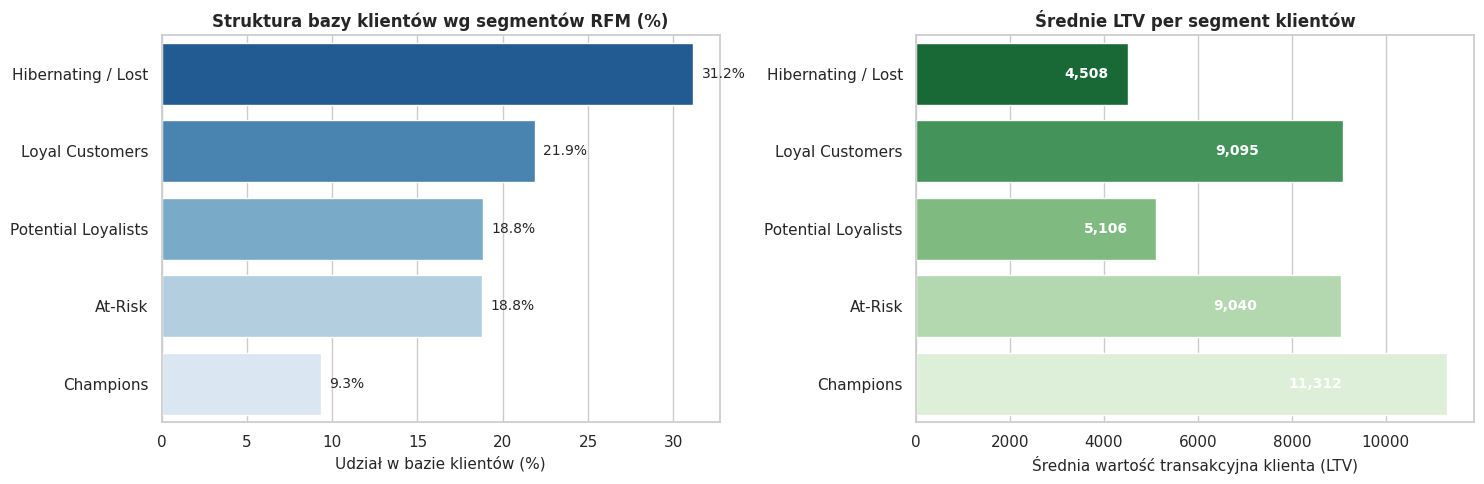

,Segment,Customer_Count,Share_Pct,Avg_LTV,Total_Revenue
2,Hibernating / Lost,7762,31.158926,4508.219456,34992799.42
3,Loyal Customers,5449,21.873871,9094.911909,49558174.99
4,Potential Loyalists,4694,18.843081,5105.560264,23965499.88
0,At-Risk,4681,18.790896,9040.454839,42318369.10
1,Champions,2325,9.333226,11311.578645,26299420.35


In [ ]:

# 6. Wizualizacja: Rozkład wielkości segmentów i ich średni LTV
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Wykres 1: Udział w bazie (%)
sns.barplot(data=segment_summary, y='Segment', x='Share_Pct', palette='Blues_r', ax=ax1)
ax1.set_title('Struktura bazy klientów wg segmentów RFM (%)', fontweight='bold')
ax1.set_xlabel('Udział w bazie klientów (%)')
ax1.set_ylabel('')
for p in ax1.patches:
    ax1.annotate(f"{p.get_width():.1f}%", (p.get_width() + 0.5, p.get_y() + p.get_height() / 2),
                 va='center', fontsize=10)

# Wykres 2: Średnia wartość klienta (Avg LTV)
sns.barplot(data=segment_summary, y='Segment', x='Avg_LTV', palette='Greens_r', ax=ax2)
ax2.set_title('Średnie LTV per segment klientów', fontweight='bold')
ax2.set_xlabel('Średnia wartość transakcyjna klienta (LTV)')
ax2.set_ylabel('')
for p in ax2.patches:
    ax2.annotate(f"{p.get_width():,.0f}", (p.get_width() * 0.7, p.get_y() + p.get_height() / 2),
                 va='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

# Tabela zbiorcza
display(segment_summary[['Segment', 'Customer_Count', 'Share_Pct', 'Avg_LTV', 'Total_Revenue']])

# Podsumowanie
### 1. Analiza Rentowności i Polityki Rabatowej
* **Cel:** Zbadanie wpływu wysokości udzielanych rabatów na marżę operacyjną.
* **Wynik:** Wykres trendu marży zysku ujawnił, że w miarę wzrostu wartości rabatu marża systematycznie maleje. Próg rentowności (marża < 0%) zostaje przekroczony przy bardzo wysokich wartościach nominalnych rabatów.
* **Rekomendacja:** Należy zrewidować politykę udzielania rabatów kwotowych i ograniczyć maksymalne progi zniżek, aby unikać transakcji generujących straty.

### 2. Logistyka a Zadowolenie Klientów i Zwroty
* **Cel:** Analiza wpływu czasu dostawy na wskaźnik zwrotów oraz oceny klientów.
* **Wyniki:**
  * **Wskaźnik zwrotów:** Utrzymuje się na zerowym poziomie (0.0%), co sugeruje potrzebę weryfikacji integralności bazy danych w obszarze rejestracji zwrotów.
  * **Satysfakcja klientów:** Średnia ocena klienta od początku (dnia 0) plasuje się poniżej celu satysfakcji (4.0). Wraz z upływem czasu dostawy zadowolenie sukcesywnie spada, osiągając krytycznie niski poziom (poniżej 3.3) dla zamówień dostarczanych powyżej 11 dni.
* **Rekomendacja:** Optymalizacja procesów logistycznych w celu skrócenia czasu wysyłki do maksymalnie 3-4 dni, co pozwoli powstrzymać spadek lojalności klientów.

### 3. Segmentacja Klientów RFM (Recency, Frequency, Monetary)
* **Cel:** Klasyfikacja klientów według świeżości zakupów, częstotliwości oraz łącznej wartości transakcji.
* **Struktura bazy i wyniki:**
  * **Hibernating / Lost (31.2% bazy):** Największa grupa (7,762 klientów). Niski priorytet ze względu na najniższe średnie LTV (~4,508).
  * **Loyal Customers (21.9% bazy):** Trzon biznesu (5,449 klientów) o wysokim LTV (~9,095). Wygenerowali najwyższy łączny przychód (**49.5 mln**).
  * **Potential Loyalists (18.8% bazy):** Nowi klienci o średnim LTV (~5,106) – idealna grupa do programów lojalnościowych.
  * **At-Risk (18.8% bazy):** Kluczowy segment (4,681 klientów) o bardzo wysokim historycznym LTV (~9,040). Dawno nic nie kupili i wymagają natychmiastowych kampanii reaktywacyjnych.
  * **Champions (9.3% bazy):** Najbardziej wartościowa grupa VIP (2,325 klientów) o najwyższym LTV (~11,312).


# Przygotowanie danych do eksportu

In [ ]:
# Dołączenie segmentu RFM do każdej transakcji (Merge po Customer_ID)
customer_id_col = 'customer_id' if 'customer_id' in df.columns else 'Customer_ID'
df_sales = df.copy()

# Przygotowanie rfm do złączenia
df_rfm_to_merge = rfm[['Customer_ID', 'Segment']].rename(columns={'Customer_ID': customer_id_col, 'Segment': 'RFM_Segment'})

df_master = df_sales.merge(df_rfm_to_merge, on=customer_id_col, how='left')

# Dodanie przedziałów rabatowych do każdego wiersza
discount_col = 'discount_amount' if 'discount_amount' in df_master.columns else ('discount' if 'discount' in df_master.columns else None)

if discount_col in df_master.columns:
    max_discount = df_master[discount_col].max()
    discount_values = df_master[discount_col] * 100 if max_discount <= 1.0 else df_master[discount_col]

    df_master['Discount_Bucket'] = pd.cut(
        discount_values,
        bins=[-1, 0, 5, 10, 15, 20, 25, 30, 50, 10000],
        labels=['0% (Brak)', '1-5%', '6-10%', '11-15%', '16-20%', '21-25%', '26-30%', '31-50%', '50%+']
    )
else:
    df_master['Discount_Bucket'] = 'Nieznany'

# Dodanie grup czasu dostawy do każdego wiersza z obsługą NaN
delivery_days_col = 'delivery_days' if 'delivery_days' in df_master.columns else 'Delivery_Days'
if delivery_days_col in df_master.columns:
    # Zabezpieczamy wartości null przed podziałem
    bins = [-1, 3, 7, 10, 10000] # Zwiększono limit na wypadek skrajnych wartości
    labels = ['0-3 dni', '4-7 dni', '8-10 dni', '11+ dni']

    # Konwersja do typu 'object' po wycięciu przedziałów, aby dodać bezpieczną kategorię braków danych
    df_master['Delivery_Group'] = pd.cut(df_master[delivery_days_col], bins=bins, labels=labels)
    df_master['Delivery_Group'] = df_master['Delivery_Group'].astype(str).replace('nan', 'Brak informacji')
else:
    df_master['Delivery_Group'] = 'Nieznany'


In [ ]:
# Ponowne przeliczenie braków danych po wprowadzeniu poprawek
existing_keys = [col for col in key_columns if col in df_master.columns]

nan_report = pd.DataFrame({
    'Kolumna': existing_keys,
    'Liczba braków (NaN)': [df_master[col].isnull().sum() for col in existing_keys],
    'Procent braków (%)': [(df_master[col].isnull().sum() / len(df_master)) * 100 for col in existing_keys]
})

print("📊 Zaktualizowany raport braków danych w pliku Master:")
display(nan_report)

📊 Zaktualizowany raport braków danych w pliku Master:


,Kolumna,Liczba braków (NaN),Procent braków (%)
0,order_id,0,0.0
1,customer_id,0,0.0
2,RFM_Segment,0,0.0
3,Discount_Bucket,0,0.0
4,Delivery_Group,0,0.0
5,net_sales,0,0.0


In [ ]:
import os

# Definiowanie ścieżki docelowej
target_dir = '/content/drive/MyDrive/data_e_comer/exporrt/2'
os.makedirs(target_dir, exist_ok=True)

target_file_path = os.path.join(target_dir, 'tableau_master_transactions.csv')

# 5. Eksport JEDNEGO pliku Master do Tableau na Dysk Google
df_master.to_csv(target_file_path, index=False, encoding='utf-8-sig')

print(f"✅ Wygenerowano i zapisano oczyszczony plik pod ścieżką: '{target_file_path}'!")
print(f"Wymiary pliku master: {df_master.shape[0]:,} wierszy, {df_master.shape[1]} kolumn.")

✅ Wygenerowano i zapisano oczyszczony plik pod ścieżką: '/content/drive/MyDrive/data_e_comer/exporrt/2/tableau_master_transactions.csv'!
Wymiary pliku master: 138,116 wierszy, 51 kolumn.
